# Week 8 - Student Performance Visualisation

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("/content/drive/MyDrive/Python Programs/Studentperformance_preprocessed.csv", keep_default_na=False)
df['parental level of education'] = df['parental level of education'].str.replace("'S", "'s")
score_columns = ['math score', 'reading score', 'writing score']
edu_order = ['Some High School', 'High School', 'Some College', "Associate's Degree", "Bachelor's Degree", "Master's Degree"]
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Score,Percentage,Performance Band,math score outlier,reading score outlier,writing score outlier,Total Score outlier,Outlier Subjects
0,Female,Group B,Bachelor's Degree,Standard,None,72,72,74,218,72.67,Good (60-75),Normal,Normal,Normal,Normal,0
1,Female,Group C,Some College,Standard,Completed,69,90,88,247,82.33,Very Good (75-90),Normal,Normal,Normal,Normal,0
2,Female,Group B,Master's Degree,Standard,None,90,95,93,278,92.67,Excellent (90+),Normal,Normal,Normal,Normal,0
3,Male,Group A,Associate's Degree,Free/Reduced,None,47,57,44,148,49.33,Average (40-60),Normal,Normal,Normal,Normal,0
4,Male,Group C,Some College,Standard,None,76,78,75,229,76.33,Very Good (75-90),Normal,Normal,Normal,Normal,0


## 1. Grouped bar charts

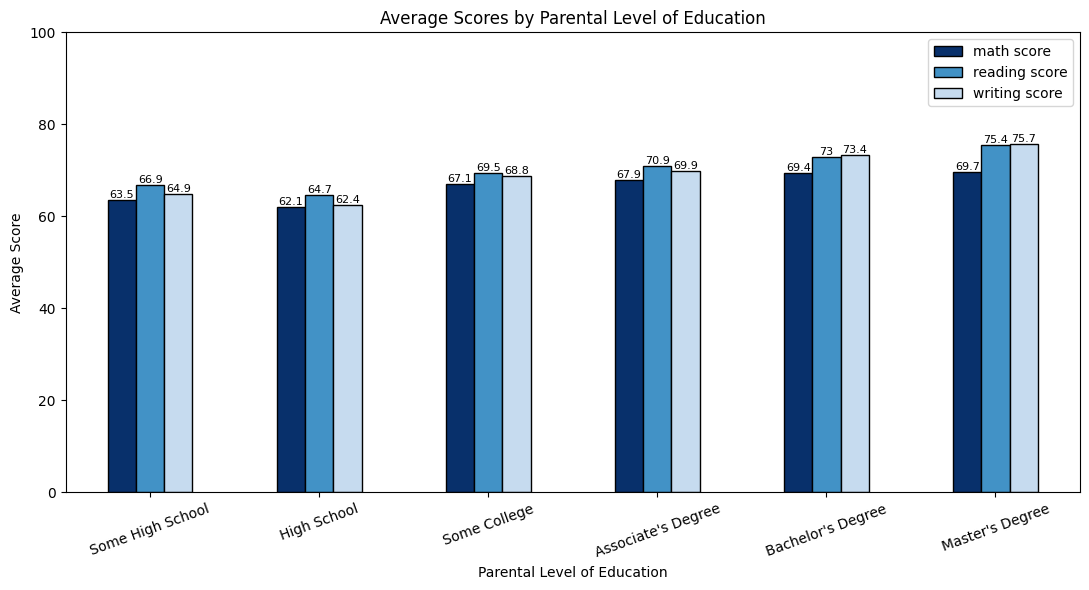

,math score,reading score,writing score
parental level of education,,,
Some High School,63.5,66.9,64.9
High School,62.1,64.7,62.4
Some College,67.1,69.5,68.8
Associate's Degree,67.9,70.9,69.9
Bachelor's Degree,69.4,73.0,73.4
Master's Degree,69.7,75.4,75.7


In [10]:
edu_avg = df.groupby('parental level of education')[score_columns].mean().reindex(edu_order).round(1)
ax = edu_avg.plot(kind='bar', figsize=(11, 6), color=['#08306b', '#4292c6', '#c6dbef'], edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.title('Average Scores by Parental Level of Education')
plt.xlabel('Parental Level of Education')
plt.ylabel('Average Score')
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
edu_avg

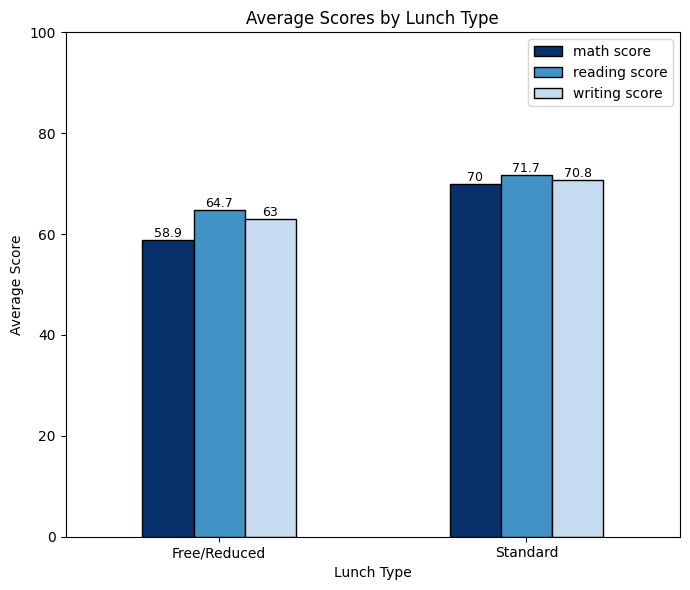

,math score,reading score,writing score
lunch,,,
Free/Reduced,58.9,64.7,63.0
Standard,70.0,71.7,70.8


In [11]:
lunch_avg = df.groupby('lunch')[score_columns].mean().round(1)
ax = lunch_avg.plot(kind='bar', figsize=(7, 6), color=['#08306b', '#4292c6', '#c6dbef'], edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fontsize=9)
plt.title('Average Scores by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
lunch_avg

## 2. Box plots - test preparation course

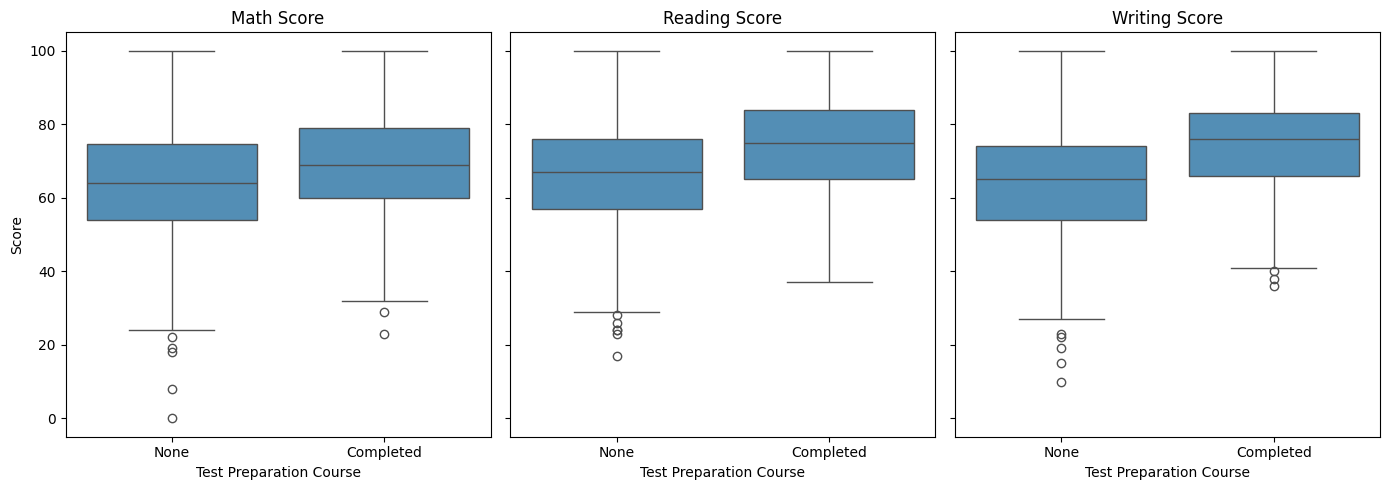

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, score_columns):
    sns.boxplot(data=df, x='test preparation course', y=col, order=['None', 'Completed'], color='#4292c6', ax=ax)
    ax.set_title(col.title())
    ax.set_xlabel('Test Preparation Course')
    ax.set_ylabel('Score')
plt.tight_layout()
plt.show()

In [13]:
spread = df.groupby('test preparation course')[score_columns].agg(['mean', 'std', 'var']).round(2)
spread

math score                reading score         \
                              mean    std     var          mean    std   
test preparation course                                                  
Completed                    69.70  14.44  208.65         73.89  13.64   
None                         64.08  15.19  230.81         66.53  14.46   

                                writing score                 
                            var          mean    std     var  
test preparation course                                       
Completed                186.01         74.42  13.38  178.90  
None                     209.20         64.50  15.00  224.99

## 3. Scatter plots and correlation heatmap

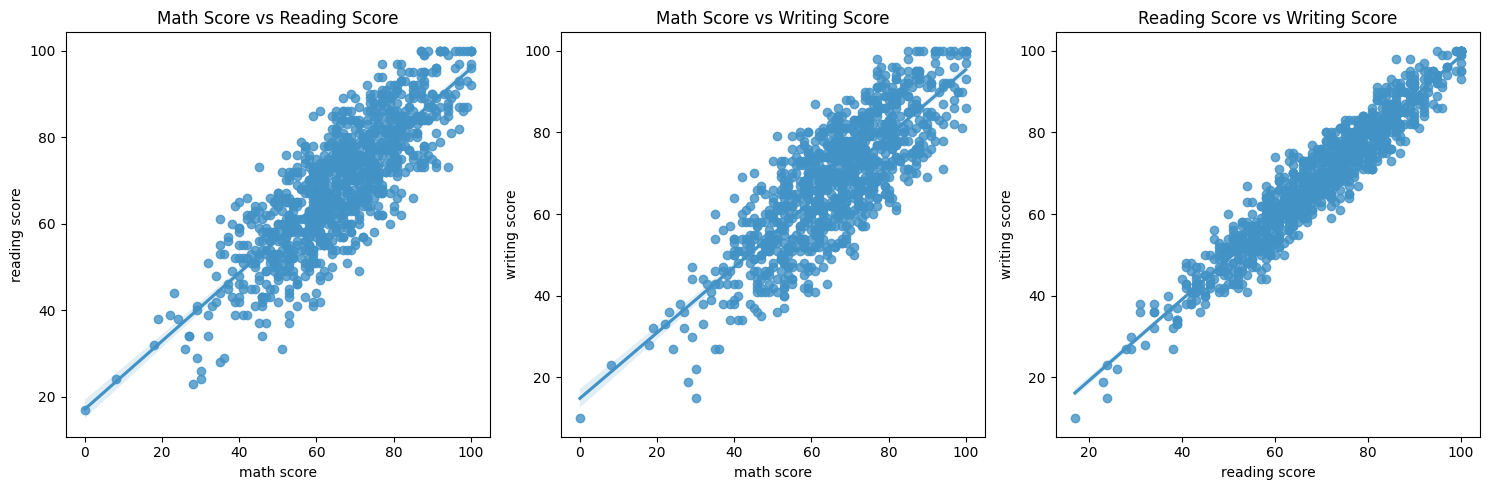

In [14]:
pairs = [('math score', 'reading score'), ('math score', 'writing score'), ('reading score', 'writing score')]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, color='#4292c6', ax=ax)
    ax.set_title(x.title() + ' vs ' + y.title())
plt.tight_layout()
plt.show()

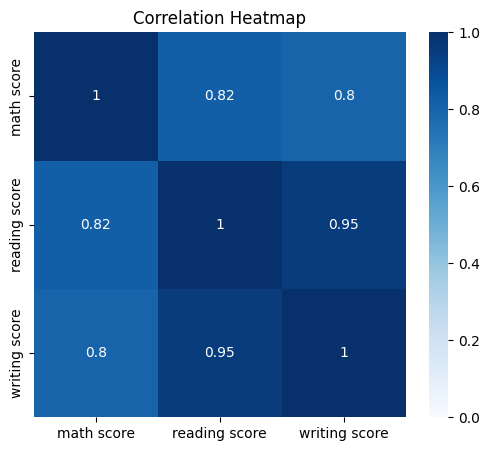

In [15]:
corr = df[score_columns].corr().round(2)
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

## 4. Educational equity and policy recommendations

In [16]:
df['at_risk'] = df['Percentage'] < 60
print(df.groupby('lunch')[['Percentage', 'at_risk']].mean().round(2))
print()
print(df.groupby('test preparation course')[['Percentage', 'at_risk']].mean().round(2))
print()
print(df.groupby('parental level of education')[['Percentage', 'at_risk']].mean().reindex(edu_order).round(2))

              Percentage  at_risk
lunch                            
Free/Reduced       62.20     0.44
Standard           70.84     0.20

                         Percentage  at_risk
test preparation course                     
Completed                     72.67     0.17
None                          65.04     0.35

                             Percentage  at_risk
parental level of education                     
Some High School                  65.11     0.36
High School                       63.10     0.39
Some College                      68.48     0.24
Associate's Degree                69.57     0.27
Bachelor's Degree                 71.92     0.18
Master's Degree                   73.60     0.17


### Key findings
- **Lunch type:** Standard lunch students average 70.8% overall; free/reduced lunch students average 62.2%. The gap is biggest in Math (about 11 points). 43.7% of free/reduced lunch students score below 60%, compared to 20.2% of standard lunch students.
- **Parental education:** Scores go up as parental education goes up in all three subjects. Students whose parents have a Master's degree average 73.6% overall, compared to about 63-65% for parents with high school or less. The difference is biggest in Writing (about 13 points) and smallest in Math (about 8 points).
- **Test preparation:** Students who completed the course score about 7.6 points higher overall (72.7% vs 65.0%), and their scores are less spread out. Only 16.8% of them score below 60%, compared to 35.0% of students who did not take it.
- **Subject relationships:** Reading and Writing are very strongly related (r = 0.95). Math is also strongly related to both (r = 0.80 to 0.82), so a student who is weak in one subject is usually weak in the others.
- **Combined effect:** Free/reduced lunch students who did the test prep course average 67.8%, almost the same as standard lunch students who did not (68.3%).

### Recommendations
1. **Make test preparation free and easy to join.** About 64% of students do not take it, even though it is linked to higher and more consistent scores. Offer it during or right after school hours, and prioritise free/reduced lunch students.
2. **Give extra Math support to lower-income students.** The largest lunch-type gap is in Math, so small-group tutoring or Math labs would help most there.
3. **Support first-generation students in Reading and Writing.** The gap by parental education is largest in these subjects, so offer reading programs, writing workshops and homework help for students whose parents did not attend college.
4. **Identify struggling students early.** Because the subjects are strongly related, a low score in one subject is a warning sign for the others. Track these students and support them across subjects.
5. **Reduce cost barriers.** Provide free study materials and a quiet study space for students who need them.

### Limitations
- This data shows relationships, not proof of cause. Students who take the test prep course may already differ in motivation or home support.
- Lunch type and parental education only roughly represent a family's situation, and many students in every group do very well.
- The dataset is a public sample with 1,000 students, so the results should be checked against real school data before making decisions.